In [1]:
import sys; sys.path.append("..")
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from src.utils import evaluate, month_to_season
from src.features import FEATURE_SETS
data = pd.read_csv("../data/processed/delhi_features_daily.csv",
parse_dates=["Date", "target_date"])
md = data.dropna(subset=["target_next_day"]).copy().reset_index(drop=True)
y = md["target_next_day"]
td = md["target_date"]
m_train = td < "2024-01-01"
m_val =(td >= "2024-01-01")& (td < "2025-01-01")
m_test =(td >= "2025-01-01") &(td < "2026-01-01")
m_trval = td < "2025-01-01" # train+ validation
# ONE common evaluation mask forevery model (baselines,ARIMA, ML)
common = md[["PM2.5", "pm25_roll7"]].notna().all(axis=1)
print(m_train.sum(), m_val.sum(), m_test.sum(),common.mean())

1410 363 356 0.9859088774072334


In [2]:
rows = []
for name, col in [("Persistence", "PM2.5"), ("7-day mean", "pm25_roll7")]:
    mk = m_val & common
    rows.append({"model": name, **evaluate(y[mk],md.loc[mk, col])})
val_table =pd.DataFrame(rows).set_index("model")
display(val_table)

,MAE,RMSE,R2,n
model,,,,
Persistence,24.748202,39.964954,0.704555,362
7-day mean,29.920289,46.268179,0.604012,362


In [4]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
def make_pipe(kind):
    imp = ("imputer", SimpleImputer(strategy="median")) #fitted on training rowsonly
    if kind =="ridge":
        return Pipeline([imp, ("scaler", StandardScaler()), ("model", Ridge(alpha=10.0))])
    if kind =="rf":
        return Pipeline([imp, ("model", RandomForestRegressor(
            n_estimators=300,min_samples_leaf=2, random_state=42, n_jobs=-1))])
    if kind =="hgb":
        return Pipeline([imp, ("model", HistGradientBoostingRegressor(
            learning_rate=0.05, max_iter=300, max_leaf_nodes=31, random_state=42))])
rows = []
for set_name,cols in FEATURE_SETS.items():
    for kind in["ridge", "rf", "hgb"]:
        pipe = make_pipe(kind).fit(md.loc[m_train,cols], y[m_train])
        mk = m_val& common
        pred = pipe.predict(md.loc[mk, cols])
        rows.append({"set": set_name, "model": kind, **evaluate(y[mk], pred)})
ablation = pd.DataFrame(rows)
display(ablation.pivot(index="model", columns="set", values="MAE"))

set,A_pollution,B_weather,C_combined
model,,,
hgb,25.718741,35.315644,24.937492
rf,23.724238,37.422906,23.923909
ridge,24.580190,44.083826,24.737032


In [5]:
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.base import clone
BEST_SET = "C_combined" # decided by reading the VALIDATION ablation above,never the test
cols = FEATURE_SETS[BEST_SET]
GRIDS = {
"ridge": {"model__alpha": [0.1, 1, 10,100, 1000]},
"rf": {"model__max_depth": [6,12, None],
"model__min_samples_leaf": [2, 5, 10],
"model__max_features": [0.5, 1.0]},
"hgb": {"model__learning_rate": [0.03, 0.08],
"model__max_iter":[200, 400],
"model__max_leaf_nodes": [8, 31],
"model__min_samples_leaf": [20, 40]},
}
tuned = {}
for kind in["ridge", "rf", "hgb"]:
    gs = GridSearchCV(make_pipe(kind), GRIDS[kind],cv=TimeSeriesSplit(n_splits=4),scoring="neg_mean_absolute_error", n_jobs=-1)
    gs.fit(md.loc[m_train, cols], y[m_train]) # training rows ONLY
    tuned[kind] =gs
    print(kind, gs.best_params_,-gs.best_score_)

ridge {'model__alpha': 10} 32.07950570932029
rf {'model__max_depth': 12, 'model__max_features': 1.0, 'model__min_samples_leaf': 5} 32.01679303908839
hgb {'model__learning_rate': 0.03, 'model__max_iter': 200, 'model__max_leaf_nodes': 31, 'model__min_samples_leaf': 20} 33.30607706249116


In [6]:
rows = []
mk = m_val & common
for kind, gs in tuned.items():
    pred = gs.best_estimator_.predict(md.loc[mk,cols])
    rows.append({"model": kind, **evaluate(y[mk],pred)})
val_tuned =pd.DataFrame(rows).set_index("model").sort_values("MAE")
display(val_tuned)
FINAL_KIND = val_tuned.index[0]

,MAE,RMSE,R2,n
model,,,,
rf,24.007436,36.823710,0.749174,362
hgb,24.613011,37.977761,0.733206,362
ridge,24.737032,37.291869,0.742756,362


In [7]:
final_pipes = {}
for kind, gs in tuned.items():
    pipe = clone(gs.best_estimator_)
# frozen hyperparameters
    pipe.fit(md.loc[m_trval, cols], y[m_trval])
# target dates < 2025
    final_pipes[kind] = pipe
test_rows = md.loc[m_test]
test_table = pd.DataFrame({
"Actual": test_rows["target_next_day"].values,
"Persistence": test_rows["PM2.5"].values,
"Mean7": test_rows["pm25_roll7"].values,
}, index=pd.DatetimeIndex(test_rows["target_date"].values, name="Date"))
for kind, pipe in final_pipes.items():
    test_table[kind] = pipe.predict(test_rows[cols])
arima = pd.read_csv("../results/tables/arima_test_predictions.csv",
index_col="Date", parse_dates=True)
test_table["ARIMA"] = arima["Predicted"].reindex(test_table.index)
assert np.allclose(arima["Actual"].reindex(test_table.index).dropna(),
test_table.loc[arima["Actual"].reindex(test_table.index).notna(), "Actual"])
test_table = test_table.dropna()
# common evaluation rows for ALL models
test_table.to_csv("../results/tables/test_predictions_all_models.csv")

In [8]:
models = ["Persistence", "Mean7", "ARIMA", "ridge", "rf", "hgb"]
rows = [{"model": m, **evaluate(test_table["Actual"], test_table[m])} for m in models]
final = pd.DataFrame(rows).set_index("model")
final["MAE_skill_vs_persistence"] = 1- final["MAE"] / final.loc["Persistence", "MAE"]
display(final.round(3))
final.round(4).to_csv("../results/tables/final_comparison.csv")

,MAE,RMSE,R2,n,MAE_skill_vs_persistence
model,,,,,
Persistence,23.404,35.049,0.807,350,0.000
Mean7,27.575,41.481,0.730,350,-0.178
ARIMA,22.850,33.864,0.820,350,0.024
ridge,22.354,32.341,0.836,350,0.045
rf,22.364,32.874,0.830,350,0.044
hgb,23.119,34.737,0.811,350,0.012


In [9]:
def block_bootstrap_mae_diff(actual, pred_a, pred_b, block=7, n_boot=2000, seed=42):
    """Mean(|e_a|-|e_b|) with a 95% block-bootstrap interval. Negative => model A better."""
    rng = np.random.default_rng(seed)
    d = np.abs(actual- pred_a).to_numpy()- np.abs(actual- pred_b).to_numpy()
    n = len(d); nb = int(np.ceil(n / block))
    stats_ = []
    for _ in range(n_boot):
        starts = rng.integers(0, n- block + 1, nb)
        sample = np.concatenate([d[s:s + block] for s in starts])[:n]
        stats_.append(sample.mean())
    return d.mean(), np.percentile(stats_, [2.5, 97.5])
print(block_bootstrap_mae_diff(test_table["Actual"],
test_table[FINAL_KIND], test_table["Persistence"]))   

(np.float64(-1.0400822335379365), array([-2.580222 ,  0.7287826]))


In [10]:
from sklearn.inspection import permutation_importance
rf_train = clone(tuned["rf"].best_estimator_).fit(md.loc[m_train, cols], y[m_train])
mk = m_val & common
res = permutation_importance(rf_train, md.loc[mk, cols], y[mk], n_repeats=10,
random_state=42, scoring="neg_mean_absolute_error")
importance = pd.Series(res.importances_mean, index=cols).sort_values(ascending=False)
print(importance.head(15))

PM2.5              35.692082
wind_speed_max      0.687538
pm25_roll7          0.346784
pm25_lag_1          0.275500
wind_u_mean         0.275232
wind_v_mean         0.231193
wind_speed_mean     0.220207
pm25_lag_7          0.216282
temperature_min     0.166575
dew_point_mean      0.141065
PM10                0.112494
pressure_change     0.110732
month_sin           0.083728
SO2                 0.083662
NO2                 0.067598
dtype: float64


In [11]:
test_table["season"] = test_table.index.month.map(month_to_season)
rows = []
for season, g in test_table.groupby("season"):
    for m in ["Persistence", "ARIMA", FINAL_KIND]:
        r = evaluate(g["Actual"], g[m])
        rows.append({"season": season, "model": m, "MAE": r["MAE"],
            "RMSE": r["RMSE"], "n": r["n"]})
season_error = pd.DataFrame(rows)
display(season_error.pivot(index="season", columns="model", values="MAE").round(2))

model,ARIMA,Persistence,rf
season,,,
Monsoon,10.52,8.39,8.21
Post-Monsoon,29.79,32.23,30.57
Summer,17.67,18.65,17.32
Winter,38.10,40.13,38.79


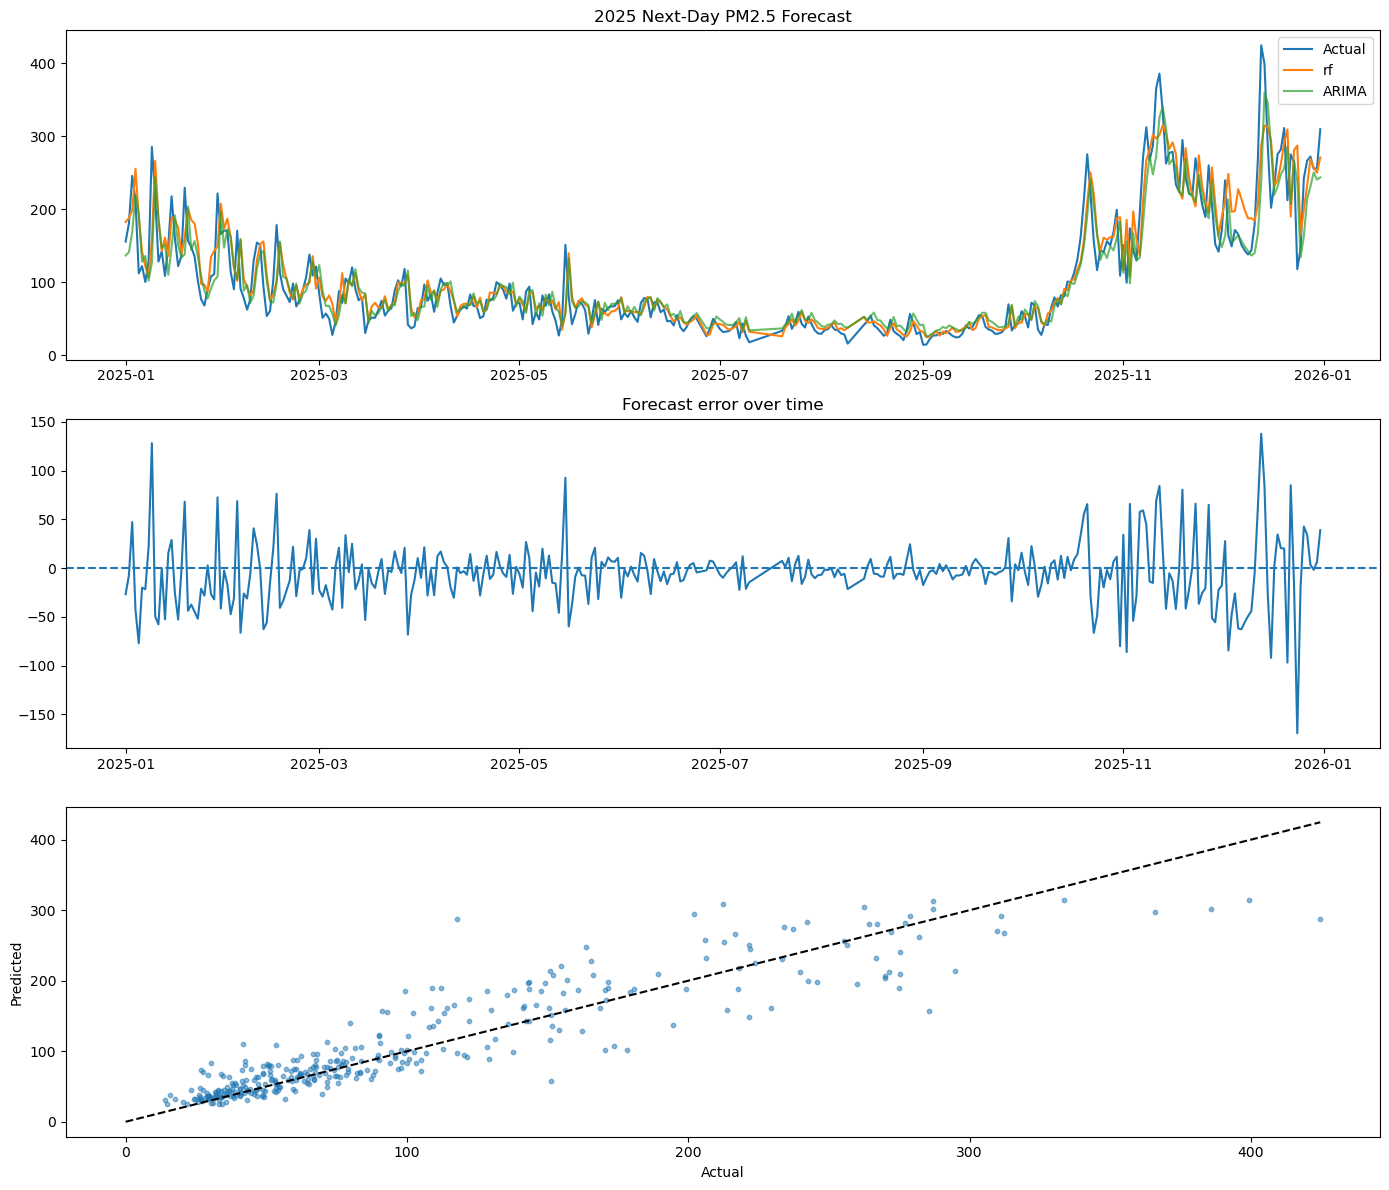

In [12]:
fig, axes = plt.subplots(3, 1, figsize=(14, 12))
axes[0].plot(test_table.index, test_table["Actual"], label="Actual")
axes[0].plot(test_table.index, test_table[FINAL_KIND], label=FINAL_KIND)
axes[0].plot(test_table.index, test_table["ARIMA"], label="ARIMA", alpha=0.7)
axes[0].set_title("2025 Next-Day PM2.5 Forecast"); axes[0].legend()
err = test_table["Actual"]- test_table[FINAL_KIND]
axes[1].plot(err.index, err); axes[1].axhline(0, ls="--")
axes[1].set_title("Forecast error over time")
axes[2].scatter(test_table["Actual"], test_table[FINAL_KIND], s=10, alpha=0.5)
lim = [0, test_table["Actual"].max()]
axes[2].plot(lim, lim, "k--"); axes[2].set_xlabel("Actual"); axes[2].set_ylabel("Predicted")
plt.tight_layout(); plt.show()